# Week 7 Advanced Models

## Goal

This notebook will:

1. load the Week 6 feature data;
2. train an **XGBoost** home price model;
3. try a small number of model settings;
4. choose the best settings using a validation set;
5. report the final test results;
6. save the Week 7 result files in `results/05/`.

The main test measures are **R², MAE, RMSE, and MdAPE**.

## 1. Import the packages

The code below installs XGBoost only when it is missing.

In [1]:
from pathlib import Path
import subprocess
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

try:
    from xgboost import XGBRegressor
except ImportError:
    print("XGBoost is not installed. Installing it now...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost"])
    from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

print("Packages are ready.")

Packages are ready.


## 2. Set the file paths

The notebook expects the Week 6 file at:

`results/Week 6 Updated notebook + table comparing/feature_engineered_data.csv`

All new files will be saved in:

`results/05/`

In [2]:
working_dir = Path.cwd()

# This works when the notebook is in the main project folder
# or inside a folder named "notebooks".
project_root = (
    working_dir.parent
    if working_dir.name.lower() == "notebooks"
    else working_dir
)

data_path = project_root / "results" / "Week 6 Updated notebook + table comparing" / "feature_engineered_data.csv"
results_dir = project_root / "results" / "05"
results_dir.mkdir(parents=True, exist_ok=True)

print("Input file:", data_path)
print("Output folder:", results_dir)

Input file: C:\Users\18327\IDX Exchange\results\Week 6 Updated notebook + table comparing\feature_engineered_data.csv
Output folder: C:\Users\18327\IDX Exchange\results\05


## 3. Load the Week 6 data

In [3]:
if not data_path.exists():
    raise FileNotFoundError(
        f"Cannot find {data_path}. "
        "Run the Week 6 notebook first and make sure "
        "feature_engineered_data.csv is inside results/Week 6 Updated notebook + table comparing/."
    )

df = pd.read_csv(data_path, low_memory=False)
df.columns = df.columns.str.strip()

print("Data shape:", df.shape)
display(df.head())

Data shape: (23260, 81)


,BuyerAgentAOR,ListAgentAOR,Flooring,ViewYN,WaterfrontYN,BasementYN,PoolPrivateYN,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,PropertyType,LivingArea,ListPrice,DaysOnMarket,ListOfficeName,BuyerOfficeName,CoListOfficeName,ListAgentFullName,CoListAgentFirstName,CoListAgentLastName,BuyerAgentMlsId,BuyerAgentFirstName,BuyerAgentLastName,FireplacesTotal,AssociationFeeFrequency,AboveGradeFinishedArea,ListingKeyNumeric,MLSAreaMajor,TaxAnnualAmount,CountyOrParish,MlsStatus,ElementarySchool,AttachedGarageYN,ParkingTotal,BuilderName,PropertySubType,LotSizeAcres,SubdivisionName,BuyerOfficeAOR,YearBuilt,StreetNumberNumeric,ListingId,BathroomsTotalInteger,City,TaxYear,BuildingAreaTotal,BedroomsTotal,ContractStatusChangeDate,ElementarySchoolDistrict,CoBuyerAgentFirstName,PurchaseContractDate,ListingContractDate,BelowGradeFinishedArea,BusinessType,StateOrProvince,CoveredSpaces,MiddleOrJuniorSchool,FireplaceYN,Stories,HighSchool,Levels,LotSizeDimensions,LotSizeArea,MainLevelBedrooms,NewConstructionYN,GarageSpaces,HighSchoolDistrict,PostalCode,AssociationFee,LotSizeSquareFeet,MiddleOrJuniorSchoolDistrict,DistrictName,bed_bath_ratio,property_age
0,OutOfAreaBoard,CitrusValley,NaN,True,NaN,NaN,False,"635,000.0000",1171672853,mike@bhfmortgage.com,2026-05-26,"635,000.0000",Michael,Wallace,33.7653,-118.1783,1140 E Ocean,Residential,684.0000,"635,000.0000",0,"BETTER HOME FINANCIAL, INC",Compass,NaN,Michael Wallace,NaN,NaN,CLW-C145499,Zara,Baghikyan,NaN,Monthly,NaN,1171672853,"4 - Downtown Area, Alamitos Beach",NaN,Los Angeles,Closed,NaN,False,1.0000,NaN,Condominium,1.3120,Alamitos Beach (AB),OutOfAreaBoard,"1,973.0000","1,140.0000",CV26118073,1.0000,Long Beach,NaN,NaN,1.0000,2026-05-26,NaN,NaN,2026-03-15,2026-03-15,NaN,NaN,CA,NaN,NaN,False,1.0000,NaN,One,NaN,"57,149.0000",1.0000,False,1.0000,Long Beach Unified,90802,785.0000,"57,149.0000",NaN,Long Beach Unified,1.0000,53.0000
1,SouthBay,SouthBay,Wood,True,NaN,NaN,False,"8,712,500.0000",1171668711,EK@ITZSOLD.COM,2026-05-28,"8,712,500.0000",Edward,Kaminsky,33.8890,-118.4127,212 18th Street,Residential,"4,269.0000","8,712,500.0000",0,"eXp Realty of California, Inc","eXp Realty of California, Inc",NaN,Edward Kaminsky,NaN,NaN,SKAMIEDW,Edward,Kaminsky,NaN,NaN,NaN,1171668711,142 - Manhattan Bch Sand,NaN,Los Angeles,Closed,NaN,True,4.0000,NaN,SingleFamilyResidence,0.0621,NaN,SouthBay,"2,004.0000",212.0000,SB26116787,6.0000,Manhattan Beach,NaN,NaN,5.0000,2026-05-28,NaN,NaN,2024-10-30,2024-10-30,NaN,NaN,CA,NaN,NaN,True,NaN,NaN,ThreeOrMore,NaN,"2,703.0000",2.0000,False,4.0000,Manhattan Unified,90266,0.0000,"2,703.0000",NaN,Manhattan Beach Unified,0.8333,22.0000
2,PacificWest,SouthBay,NaN,True,NaN,NaN,True,"4,194.0000",1171656528,James.daniel@exprealty.com,2026-05-29,"4,194.0000",James,Daniel,33.7670,-118.3082,27885 S Lauren,ResidentialLease,"1,600.0000","4,194.0000",0,"eXp Realty of Greater Los Angeles, Inc.",Keller Williams Pacific Estate,NaN,James Daniel,NaN,NaN,PWBRIDAR,Darnisha,Brim,NaN,NaN,NaN,1171656528,193 - San Pedro - North,NaN,Los Angeles,Closed,NaN,True,2.0000,NaN,Townhouse,0.0000,NaN,PacificWest,"2,023.0000","27,885.0000",SB26118017,3.0000,San Pedro,NaN,NaN,3.0000,2026-05-29,NaN,NaN,2026-05-29,2026-05-05,NaN,NaN,CA,NaN,NaN,False,NaN,NaN,ThreeOrMore,NaN,0.0000,3.0000,False,2.0000,Los Angeles Unified,90732,0.0000,0.0000,NaN,Los Angeles Unified,1.0000,3.0000
3,SanDiego,SanDiego,NaN,False,NaN,NaN,False,"1,100,000.0000",1171617616,cmorton@crownrealtyteam.com,2026-05-29,"1,100,000.0000",Carrie,Morton,32.6635,-117.0494,3705 Alameda Way,Residential,"1,958.0000","1,100,000.0000",0,"Crown Investment Realty, Inc.","Crown Investment Realty, Inc.",NaN,Carrie Morton,NaN,NaN,SAND-667400,Carrie,Morton,NaN,NaN,NaN,1171617616,91902 - Bonita,NaN,San Diego,Closed,NaN,NaN,4.0000,NaN,SingleFamilyResidence,1.0914,Bonita,SanDiego,"1,956.0000","3,705.0000",260013195SD,3.0000,Bonita,NaN,NaN,4.0000,2026-05-29,NaN,NaN,2026-04-27,2026-0

## 4. Find the important columns

The code checks a few common column names. This makes the notebook work with small name differences such as `ClosePrice` versus `SalePrice`.

In [4]:
def first_existing(candidates):
    # Return the first column name that exists in the data.
    for column in candidates:
        if column in df.columns:
            return column
    return None


def clean_number(series):
    # Change money or text values into numbers.
    return pd.to_numeric(
        series.astype(str).str.replace(r"[^0-9.\-]", "", regex=True),
        errors="coerce",
    )


target_col = first_existing(
    ["ClosePrice", "SoldPrice", "SalePrice", "CurrentPrice", "price"]
)

bed_col = first_existing(
    ["BedroomsTotal", "Bedrooms", "BedsTotal", "Beds", "bedrooms"]
)

bath_col = first_existing(
    [
        "BathroomsTotalInteger",
        "BathroomsTotalDecimal",
        "BathroomsFull",
        "Bathrooms",
        "BathsTotal",
        "Baths",
        "bathrooms",
    ]
)

year_built_col = first_existing(
    ["YearBuilt", "year_built", "BuiltYear"]
)

bed_bath_col = first_existing(
    ["bed_bath_ratio", "BedBathRatio"]
)

property_age_col = first_existing(
    ["property_age", "PropertyAge"]
)

school_district_col = first_existing(
    ["DistrictName", "SchoolDistrict", "SchoolDistrictName", "district_name"]
)

required_columns = {
    "target price": target_col,
    "bed/bath ratio": bed_bath_col,
    "property age": property_age_col,
    "school district": school_district_col,
}

missing_items = [name for name, column in required_columns.items() if column is None]

if missing_items:
    raise ValueError(
        "The Week 6 data is missing these required items: "
        f"{missing_items}. Please check the Week 6 output file."
    )

print("Target column:", target_col)
print("Bed/bath ratio column:", bed_bath_col)
print("Property age column:", property_age_col)
print("School district column:", school_district_col)

Target column: ClosePrice
Bed/bath ratio column: bed_bath_ratio
Property age column: property_age
School district column: DistrictName


## 5. Choose the model features

The model uses the same type of property features used in Week 6. It also includes the three new Week 6 features:

1. bed and bath ratio;
2. property age;
3. school district.

Only columns that are actually in the data are kept.

In [5]:
numeric_candidates = [
    bed_col,
    bath_col,
    year_built_col,
    "LivingArea",
    "BuildingAreaTotal",
    "LotSizeSquareFeet",
    "LotSizeArea",
    "Latitude",
    "Longitude",
    "ListPrice",
    "OriginalListPrice",
    "DaysOnMarket",
    "CumulativeDaysOnMarket",
    "GarageSpaces",
    "Stories",
    bed_bath_col,
    property_age_col,
]

numeric_features = []

for column in numeric_candidates:
    if (
        column is not None
        and column in df.columns
        and column != target_col
        and column not in numeric_features
    ):
        numeric_features.append(column)
        df[column] = clean_number(df[column])

categorical_features = [school_district_col]

df[target_col] = clean_number(df[target_col])
df[school_district_col] = (
    df[school_district_col]
    .replace("", np.nan)
    .fillna("Unknown")
    .astype(str)
)

if not numeric_features:
    raise ValueError("No numeric model features were found.")

print("Numeric features:")
print(numeric_features)
print("\nCategory feature:")
print(categorical_features)

Numeric features:
['BedroomsTotal', 'BathroomsTotalInteger', 'YearBuilt', 'LivingArea', 'BuildingAreaTotal', 'LotSizeSquareFeet', 'LotSizeArea', 'Latitude', 'Longitude', 'ListPrice', 'OriginalListPrice', 'DaysOnMarket', 'GarageSpaces', 'Stories', 'bed_bath_ratio', 'property_age']

Category feature:
['DistrictName']


## 6. Prepare the model data

Rows without a valid positive sale price are removed.

In [6]:
model_df = df[
    df[target_col].notna()
    & (df[target_col] > 0)
].copy()

feature_columns = numeric_features + categorical_features

X = model_df[feature_columns].copy()
y = model_df[target_col].copy()

print("Rows used for modeling:", len(model_df))
print("Number of raw features:", len(feature_columns))

Rows used for modeling: 23260
Number of raw features: 17


## 7. Make the training and test sets

When the data already has a `split` column with `train` and `test`, the notebook keeps that split.

When there is no usable `split` column, it uses an 80% training and 20% test split with `random_state=42`.

In [7]:
split_col = first_existing(["split", "Split"])
use_saved_split = False

if split_col is not None:
    split_values = model_df[split_col].astype(str).str.strip().str.lower()
    use_saved_split = {"train", "test"}.issubset(set(split_values.unique()))

if use_saved_split:
    train_mask = split_values == "train"
    test_mask = split_values == "test"

    X_train = X.loc[train_mask].copy()
    X_test = X.loc[test_mask].copy()
    y_train = y.loc[train_mask].copy()
    y_test = y.loc[test_mask].copy()

    split_method = "Saved train/test split"
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
    )

    split_method = "Random 80/20 split"

if X_train.empty or X_test.empty:
    raise ValueError("The training set or test set is empty.")

print("Split method:", split_method)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Split method: Random 80/20 split
Training rows: 18608
Test rows: 4652


## 8. Create a small validation set

The validation set is used to choose the model settings. The final test set is not used during this step.

In [8]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
)

print("Rows used to fit each trial model:", len(X_fit))
print("Validation rows:", len(X_valid))

Rows used to fit each trial model: 14886
Validation rows: 3722


## 9. Prepare numeric and category data

Missing numeric values are filled with the median. School district names are changed into 0/1 columns.

XGBoost does not need numeric features to be scaled.

In [9]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

category_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("school_district", category_pipeline, categorical_features),
    ]
)

X_fit_ready = preprocessor.fit_transform(X_fit)
X_valid_ready = preprocessor.transform(X_valid)

print("Prepared training shape:", X_fit_ready.shape)
print("Prepared validation shape:", X_valid_ready.shape)

Prepared training shape: (14886, 280)
Prepared validation shape: (3722, 280)


## 10. Try a few XGBoost settings

The three settings below control the model:

1. `max_depth` controls how deep each tree can grow;
2. `learning_rate` controls how large each update is;
3. `n_estimators` controls how many trees are used.

This is a light search with only six combinations.

In [10]:
parameter_settings = [
    {"max_depth": 3, "learning_rate": 0.05, "n_estimators": 150},
    {"max_depth": 3, "learning_rate": 0.10, "n_estimators": 100},
    {"max_depth": 5, "learning_rate": 0.05, "n_estimators": 200},
    {"max_depth": 5, "learning_rate": 0.10, "n_estimators": 150},
    {"max_depth": 7, "learning_rate": 0.05, "n_estimators": 200},
    {"max_depth": 7, "learning_rate": 0.10, "n_estimators": 100},
]

parameter_settings

[{'max_depth': 3, 'learning_rate': 0.05, 'n_estimators': 150},
 {'max_depth': 3, 'learning_rate': 0.1, 'n_estimators': 100},
 {'max_depth': 5, 'learning_rate': 0.05, 'n_estimators': 200},
 {'max_depth': 5, 'learning_rate': 0.1, 'n_estimators': 150},
 {'max_depth': 7, 'learning_rate': 0.05, 'n_estimators': 200},
 {'max_depth': 7, 'learning_rate': 0.1, 'n_estimators': 100}]

In [11]:
tuning_results = []

for setting in parameter_settings:
    trial_model = XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        tree_method="hist",
        subsample=0.90,
        colsample_bytree=0.90,
        verbosity=0,
        **setting,
    )

    trial_model.fit(X_fit_ready, y_fit)
    validation_prediction = trial_model.predict(X_valid_ready)

    validation_mae = mean_absolute_error(y_valid, validation_prediction)
    validation_rmse = np.sqrt(
        mean_squared_error(y_valid, validation_prediction)
    )
    validation_r2 = r2_score(y_valid, validation_prediction)

    tuning_results.append(
        {
            **setting,
            "Validation_MAE": validation_mae,
            "Validation_RMSE": validation_rmse,
            "Validation_R2": validation_r2,
        }
    )

    print(
        f"Finished: depth={setting['max_depth']}, "
        f"learning_rate={setting['learning_rate']}, "
        f"n_estimators={setting['n_estimators']}"
    )

print("All settings are finished.")

Finished: depth=3, learning_rate=0.05, n_estimators=150
Finished: depth=3, learning_rate=0.1, n_estimators=100
Finished: depth=5, learning_rate=0.05, n_estimators=200
Finished: depth=5, learning_rate=0.1, n_estimators=150
Finished: depth=7, learning_rate=0.05, n_estimators=200
Finished: depth=7, learning_rate=0.1, n_estimators=100
All settings are finished.


## 11. Select the best settings

The best setting has the lowest validation RMSE.

In [12]:
tuning_results_df = (
    pd.DataFrame(tuning_results)
    .sort_values("Validation_RMSE")
    .reset_index(drop=True)
)

display(tuning_results_df)

tuning_results_path = results_dir / "xgboost_tuning_results.csv"
tuning_results_df.to_csv(tuning_results_path, index=False)

best_row = tuning_results_df.iloc[0]

best_params = {
    "max_depth": int(best_row["max_depth"]),
    "learning_rate": float(best_row["learning_rate"]),
    "n_estimators": int(best_row["n_estimators"]),
}

print("Best settings:")
print(best_params)
print("Saved:", tuning_results_path)

,max_depth,learning_rate,n_estimators,Validation_MAE,Validation_RMSE,Validation_R2
0,3,0.1000,100,"136,677.7958","572,710.3364",0.7051
1,3,0.0500,150,"135,136.5060","584,350.6753",0.6930
2,5,0.1000,150,"133,078.7324","2,397,884.7252",-4.1699
3,7,0.1000,100,"127,493.6047","2,509,378.7634",-4.6619
4,5,0.0500,200,"128,249.4626","2,583,119.5092",-4.9995
5,7,0.0500,200,"127,379.4982","2,772,145.9623",-5.9097


Best settings:
{'max_depth': 3, 'learning_rate': 0.1, 'n_estimators': 100}
Saved: C:\Users\18327\IDX Exchange\results\05\xgboost_tuning_results.csv


## 12. Train the final model

The final model uses all training rows and the best settings found above.

In [13]:
final_preprocessor = clone(preprocessor)

X_train_ready = final_preprocessor.fit_transform(X_train)
X_test_ready = final_preprocessor.transform(X_test)

final_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    subsample=0.90,
    colsample_bytree=0.90,
    verbosity=0,
    **best_params,
)

final_model.fit(X_train_ready, y_train)

train_prediction = final_model.predict(X_train_ready)
test_prediction = final_model.predict(X_test_ready)

print("Final XGBoost model is trained.")

Final XGBoost model is trained.


## 13. Calculate the final test results

1. **R²** is better when it is higher.
2. **MAE** is the average dollar error and is better when it is lower.
3. **RMSE** gives more weight to large errors and is better when it is lower.
4. **MdAPE** is the median percentage error and is better when it is lower.

In [14]:
def mdape(y_true, y_pred):
    # Return median absolute percentage error as a percent.
    true_values = np.asarray(y_true, dtype=float)
    predicted_values = np.asarray(y_pred, dtype=float)

    nonzero = true_values != 0

    return 100 * np.median(
        np.abs(
            (true_values[nonzero] - predicted_values[nonzero])
            / true_values[nonzero]
        )
    )


train_r2 = r2_score(y_train, train_prediction)
test_r2 = r2_score(y_test, test_prediction)
test_mae = mean_absolute_error(y_test, test_prediction)
test_rmse = np.sqrt(mean_squared_error(y_test, test_prediction))
test_mdape = mdape(y_test, test_prediction)

metrics_df = pd.DataFrame(
    [
        {
            "Model": "Tuned XGBoost",
            "Split_Method": split_method,
            "Training_Rows": len(X_train),
            "Test_Rows": len(X_test),
            "Raw_Feature_Count": len(feature_columns),
            "Best_Max_Depth": best_params["max_depth"],
            "Best_Learning_Rate": best_params["learning_rate"],
            "Best_N_Estimators": best_params["n_estimators"],
            "Train_R2": train_r2,
            "Test_R2": test_r2,
            "R2_Gap": train_r2 - test_r2,
            "Test_MAE": test_mae,
            "Test_RMSE": test_rmse,
            "Test_MdAPE_Percent": test_mdape,
        }
    ]
)

display(metrics_df)

metrics_path = results_dir / "xgboost_test_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

print("Saved:", metrics_path)

,Model,Split_Method,Training_Rows,Test_Rows,Raw_Feature_Count,Best_Max_Depth,Best_Learning_Rate,Best_N_Estimators,Train_R2,Test_R2,R2_Gap,Test_MAE,Test_RMSE,Test_MdAPE_Percent
0,Tuned XGBoost,Random 80/20 split,18608,4652,17,3,0.1000,100,0.9530,-41.4827,42.4356,"332,833.7158","7,955,266.0527",9.8087


Saved: C:\Users\18327\IDX Exchange\results\05\xgboost_test_metrics.csv


## 14. Save the test predictions

In [15]:
predictions_df = pd.DataFrame(
    {
        "Actual_Price": np.asarray(y_test),
        "Predicted_Price": test_prediction,
    },
    index=y_test.index,
)

predictions_df["Error"] = (
    predictions_df["Predicted_Price"]
    - predictions_df["Actual_Price"]
)

predictions_df["Absolute_Error"] = predictions_df["Error"].abs()

predictions_df["Absolute_Percentage_Error"] = (
    100
    * predictions_df["Absolute_Error"]
    / predictions_df["Actual_Price"].replace(0, np.nan)
)

predictions_df = predictions_df.reset_index(names="Original_Row_Index")

predictions_path = results_dir / "xgboost_test_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

display(predictions_df.head())
print("Saved:", predictions_path)

,Original_Row_Index,Actual_Price,Predicted_Price,Error,Absolute_Error,Absolute_Percentage_Error
0,16519,"710,000.0000","656,224.1250","-53,775.8750","53,775.8750",7.5741
1,6366,"2,735.0000","25,009.0039","22,274.0039","22,274.0039",814.4060
2,2602,"1,755,000.0000","1,649,520.3750","-105,479.6250","105,479.6250",6.0102
3,17636,"497,950.0000","489,212.5938","-8,737.4062","8,737.4062",1.7547
4,13084,"1,200,000.0000","1,136,084.2500","-63,915.7500","63,915.7500",5.3263


Saved: C:\Users\18327\IDX Exchange\results\05\xgboost_test_predictions.csv


## 15. Plot actual price versus predicted price

Points closer to the dashed line are better predictions.

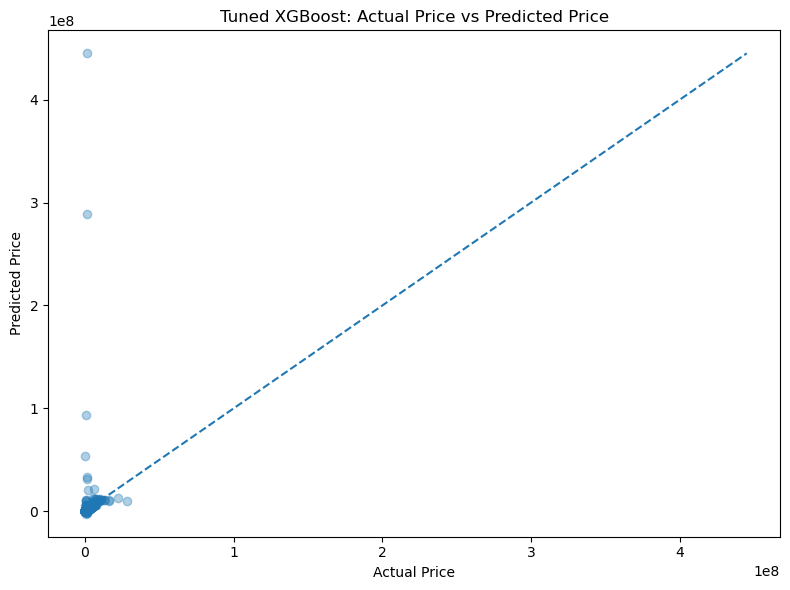

Saved: C:\Users\18327\IDX Exchange\results\05\xgboost_actual_vs_predicted.png


In [16]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, test_prediction, alpha=0.35)

line_min = min(float(np.min(y_test)), float(np.min(test_prediction)))
line_max = max(float(np.max(y_test)), float(np.max(test_prediction)))

plt.plot(
    [line_min, line_max],
    [line_min, line_max],
    linestyle="--",
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Tuned XGBoost: Actual Price vs Predicted Price")
plt.tight_layout()

prediction_plot_path = results_dir / "xgboost_actual_vs_predicted.png"
plt.savefig(prediction_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", prediction_plot_path)

## 16. Show the most important features

A larger importance value means the model used that feature more often to improve its predictions.

In [17]:
feature_names = final_preprocessor.get_feature_names_out()

clean_feature_names = [
    name.replace("numeric__", "").replace("school_district__", "")
    for name in feature_names
]

importance_df = pd.DataFrame(
    {
        "Feature": clean_feature_names,
        "Importance": final_model.feature_importances_,
    }
).sort_values("Importance", ascending=False)

importance_path = results_dir / "xgboost_feature_importance.csv"
importance_df.to_csv(importance_path, index=False)

display(importance_df.head(20))
print("Saved:", importance_path)

,Feature,Importance
15,property_age,0.4877
2,YearBuilt,0.2665
216,DistrictName_San Diego Unified,0.1214
0,BedroomsTotal,0.0265
1,BathroomsTotalInteger,0.0182
9,ListPrice,0.0174
7,Latitude,0.0148
8,Longitude,0.0113
273,DistrictName_Vista Unified,0.0101
10,OriginalListPrice,0.0068


Saved: C:\Users\18327\IDX Exchange\results\05\xgboost_feature_importance.csv


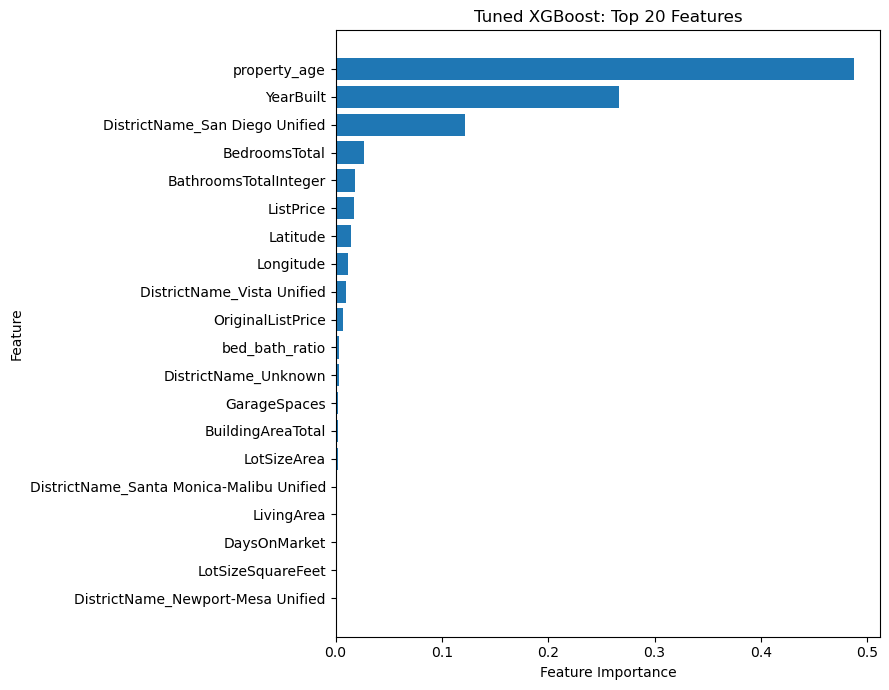

Saved: C:\Users\18327\IDX Exchange\results\05\xgboost_feature_importance.png


In [18]:
top_features = (
    importance_df.head(20)
    .sort_values("Importance", ascending=True)
)

plt.figure(figsize=(9, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Tuned XGBoost: Top 20 Features")
plt.tight_layout()

importance_plot_path = results_dir / "xgboost_feature_importance.png"
plt.savefig(importance_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", importance_plot_path)

## 17. Save the final model

The saved file contains both the data preparation steps and the trained XGBoost model.

In [19]:
model_bundle = {
    "preprocessor": final_preprocessor,
    "model": final_model,
    "target_column": target_col,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "best_parameters": best_params,
}

model_path = results_dir / "best_xgboost_model.joblib"
joblib.dump(model_bundle, model_path)

print("Saved:", model_path)

Saved: C:\Users\18327\IDX Exchange\results\05\best_xgboost_model.joblib


In [20]:
print("Week 7 is complete.")
print("Best XGBoost settings:", best_params)
print(f"Test R²: {test_r2:.4f}")
print(f"Test MAE: ${test_mae:,.2f}")
print(f"Test RMSE: ${test_rmse:,.2f}")
print(f"Test MdAPE: {test_mdape:.2f}%")
print("All files were saved in:", results_dir)

Week 7 is complete.
Best XGBoost settings: {'max_depth': 3, 'learning_rate': 0.1, 'n_estimators': 100}
Test R²: -41.4827
Test MAE: $332,833.72
Test RMSE: $7,955,266.05
Test MdAPE: 9.81%
All files were saved in: C:\Users\18327\IDX Exchange\results\05


## 18. Results

### Model setting

The tuning step tested six XGBoost settings. The selected model used a maximum depth of **3**, a learning rate of **0.10**, and **100** trees. This model had the lowest validation RMSE.

The validation MAE was **$136,677.80**. The validation RMSE was **$572,710.34**. The validation R² was **0.7051**.

### Final test results

The final model used **18,608** training rows, **4,652** test rows, and **17** original features.

1. Training R² was **0.9530**.
2. Test R² was **negative 41.4827**.
3. Test MAE was **$332,833.72**.
4. Test RMSE was **$7,955,266.05**.
5. Test MdAPE was **9.81 percent**.

The test R² and RMSE were strongly affected by a few very large prediction errors. The largest prediction was about **$444,957,200** for a home with an actual price of **$1,375,000**. The second largest prediction was about **$288,429,860** for a home with an actual price of **$1,750,000**. These two observations produced about **94.75 percent** of the total squared error.

The MdAPE gives information about a typical observation. A value of 9.81 percent means that half of the test homes had an absolute percentage error of about 9.81 percent or less. Many predictions were reasonably close, but a few extreme predictions made the overall test results poor.

### Important features

The most important feature was **property age**, with an importance value of **0.4877**. **Year built** was second, with **0.2665**. **San Diego Unified school district** was third, with **0.1214**. Bedrooms, bathrooms, list price, latitude, and longitude also helped the model. The bed and bath ratio had a smaller importance value of **0.0033**.

## 19. Conclusion

The Week 7 task is complete. The notebook trained an XGBoost model, tested six combinations of maximum depth, learning rate, and number of trees, selected the best setting with validation RMSE, and reported the final test metrics.

The model learned the training data well, but it did not give stable results for every test home. The training R² was high, while the test R² was far below zero. This shows that the final model did not generalize well to the full test set. The main reason was a small number of extreme predictions.

This model should not be used as the final home price model yet. The next step should check unusually small and unusually large sale prices, check extreme feature values, and consider using the logarithm of sale price. After cleaning these records, the XGBoost model should be trained and tested again.

The Week 7 files were saved in `results/05/`.